# Scale latitudinal gradient based on emissions

## Imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import openscm_units
import pandas as pd
import pandas_indexing as pix  # noqa: F401
import pandas_openscm
import pint
import pint_xarray
import seaborn as sns
import xarray as xr
import yaml

from cmip7_scenariomip_ghg_generation.mean_preserving_interpolation import (
    LaiKaplanInterpolator,
    interpolate_annual_mean_to_monthly,
)
from cmip7_scenariomip_ghg_generation.mean_preserving_interpolation.lai_kaplan import (
    get_wall_control_points_y_cubic,
)

## Parameters

In [2]:
ghg: str = "c8f18"
annual_mean_emissions_file: str = "../output-bundles/dev-test/data/interim/single-variable-files/c8f18_total.feather"
historical_data_root_dir: str = "../output-bundles/dev-test/data/raw/historical-ghg-concs"
historical_data_seasonality_lat_gradient_info_root: str = (
    "../output-bundles/dev-test/data/raw/historical-ghg-data-interim"
)
out_file: str = "../output-bundles/dev-test/data/interim/latitudinal-gradient/c8f18_latitudinal-gradient-info.nc"

In [3]:
# Parameters
ghg = "hfc125"
annual_mean_emissions_file = "/Users/znicholls/Documents/repos/cmip7-scenariomip-ghg-concentrations/output-bundles/1.1.0/data/interim/single-variable-files/hfc125_total.feather"
historical_data_root_dir = "/Users/znicholls/Documents/repos/cmip7-scenariomip-ghg-concentrations/output-bundles/1.1.0/data/raw/historical-ghg-concs"
historical_data_seasonality_lat_gradient_info_root = "/Users/znicholls/Documents/repos/cmip7-scenariomip-ghg-concentrations/output-bundles/1.1.0/data/raw/historical-ghg-data-interim"
out_file = "/Users/znicholls/Documents/repos/cmip7-scenariomip-ghg-concentrations/output-bundles/1.1.0/data/interim/latitudinal-gradient/hfc125_latitudinal-gradient-info.nc"


## Parse parameters

In [4]:
annual_mean_emissions_file_p = Path(annual_mean_emissions_file)
historical_data_root_dir_p = Path(historical_data_root_dir)
historical_data_seasonality_lat_gradient_info_root_p = Path(historical_data_seasonality_lat_gradient_info_root)
out_file_p = Path(out_file)

## Set up

In [5]:
ur = pint_xarray.setup_registry(openscm_units.unit_registry)
Q = ur.Quantity
pandas_openscm.register_pandas_accessor()

## Load data

### Annual-mean emissions

In [6]:
annual_mean_emissions = pd.read_feather(annual_mean_emissions_file_p)
if "hfc4310" in ghg:
    ghg_search_for = "hfc4310"
else:
    ghg_search_for = ghg

annual_mean_emissions_emms_units = annual_mean_emissions.loc[
    annual_mean_emissions.index.get_level_values("unit").str.lower().str.contains(ghg_search_for)
]
if len(annual_mean_emissions_emms_units.pix.unique("unit")) != 1:
    raise AssertionError

annual_mean_emissions_emms_units

year                                    1750  1751  1752  1753  1754  1755  \
unit         scenario variable                                               
kt HFC125/yr vl       Emissions|HFC125   0.0   0.0   0.0   0.0   0.0   0.0   
             ln       Emissions|HFC125   0.0   0.0   0.0   0.0   0.0   0.0   
             l        Emissions|HFC125   0.0   0.0   0.0   0.0   0.0   0.0   
             ml       Emissions|HFC125   0.0   0.0   0.0   0.0   0.0   0.0   
             m        Emissions|HFC125   0.0   0.0   0.0   0.0   0.0   0.0   
             h        Emissions|HFC125   0.0   0.0   0.0   0.0   0.0   0.0   
             hl       Emissions|HFC125   0.0   0.0   0.0   0.0   0.0   0.0   

year                                    1756  1757  1758  1759  ...  \
unit         scenario variable                                  ...   
kt HFC125/yr vl       Emissions|HFC125   0.0   0.0   0.0   0.0  ...   
             ln       Emissions|HFC125   0.0   0.0   0.0   0.0  ...   
             l        Emissions|HFC125   0.0   0.0   0.0   0.0  ...   
             ml       Emissions|HFC125   0.0   0.0   0.0   0.0  ...   
             m        Emissions|HFC125   0.0   0.0   0.0   0.0  ...   
             h        Emissions|HFC125   0.0   0.0   0.0   0.0  ...   
             hl       Emissions|HFC125   0.0   0.0   0.0   0.0  ...   

year                                            2491          2492  \
unit         scenario variable                                       
kt HFC125/yr vl       Emissions|HFC125  8.250378e-07  7.848002e-07   
             ln       Emissions|HFC125  1.620775e-06  1.541729e-06   
             l        Emissions|HFC125  9.740916e-06  9.265846e-06   
             ml       Emissions|HFC125  8.226755e-07  7.825532e-07   
             m        Emissions|HFC125  7.887061e-06  7.502405e-06   
             h        Emissions|HFC125  3.190719e-05  3.035106e-05   
             hl       Emissions|HFC125  1.097330e-02  1.075601e-02   

year                                            2493          2494  \
unit         scenario variable                                       
kt HFC125/yr vl       Emissions|HFC125  7.465251e-07  7.101166e-07   
             ln       Emissions|HFC125  1.466538e-06  1.395014e-06   
             l        Emissions|HFC125  8.813946e-06  8.384084e-06   
             ml       Emissions|HFC125  7.443876e-07  7.080834e-07   
             m        Emissions|HFC125  7.136508e-06  6.788456e-06   
             h        Emissions|HFC125  2.887082e-05  2.746278e-05   
             hl       Emissions|HFC125  1.054303e-02  1.033426e-02   

year                                            2495          2496  \
unit         scenario variable                                       
kt HFC125/yr vl       Emissions|HFC125  6.754838e-07  6.425401e-07   
             ln       Emissions|HFC125  1.326979e-06  1.262261e-06   
             l        Emissions|HFC125  7.975188e-06  7.586233e-06   
             ml       Emissions|HFC125  6.735498e-07  6.407004e-07   
             m        Emissions|HFC125  6.457380e-06  6.142449e-06   
             h        Emissions|HFC125  2.612340e-05  2.484935e-05   
             hl       Emissions|HFC125  1.012963e-02  9.929052e-03   

year                                            2497          2498  \
unit         scenario variable                                       
kt HFC125/yr vl       Emissions|HFC125  6.112030e-07  5.813943e-07   
             ln       Emissions|HFC125  1.200700e-06  1.142141e-06   
             l        Emissions|HFC125  7.216248e-06  6.864308e-06   
             ml       Emissions|HFC125  6.094530e-07  5.797297e-07   
             m        Emissions|HFC125  5.842879e-06  5.557918e-06   
             h        Emissions|HFC125  2.363743e-05  2.248462e-05   
             hl       Emissions|HFC125  9.732443e-03  9.539728e-03   

year                                            2499          2500  
unit         scenario variable                                  

### CMIP7 historical GHG concentrations

In [7]:
def load_file_from_glob(glob: str, base_dir: Path) -> xr.Dataset:
    """
    Load a single file based on a glob pattern
    """
    file_l = list(base_dir.rglob(glob))
    if len(file_l) != 1:
        raise AssertionError(file_l)

    ds = xr.load_dataset(file_l[0])

    return ds

In [8]:
cmip7_historical_gm_monthly_ds = load_file_from_glob(f"*{ghg}_*gm_175001-*.nc", historical_data_root_dir_p)
cmip7_historical_gm_monthly = cmip7_historical_gm_monthly_ds[ghg]
# cmip7_historical_gm_monthly

### CMIP7 historical latitudinal gradient

In [9]:
if ghg != "c8f18":
    cmip7_lat_gradient_pieces_ds = load_file_from_glob(
        f"{ghg}_allyears-lat-gradient-eofs-pcs.nc", historical_data_seasonality_lat_gradient_info_root_p
    ).pint.quantify(unit_registry=ur)

else:
    # Assume constant latitudinal gradient
    # because the historical regression doesn't make sense
    # and we didn't save the data out.
    pass

### CMIP7 historical latitudinal gradient regression info

In [10]:
if ghg != "c8f18":
    file_l = list(
        historical_data_seasonality_lat_gradient_info_root_p.rglob(f"{ghg}_pc0-total-emissions-regression.yaml")
    )
    if len(file_l) != 1:
        raise AssertionError(file_l)
    with open(file_l[0]) as fh:
        reg_info = yaml.safe_load(fh)
else:
    reg_info = {"m": (0.0, "yr / (kt C8F18)")}
# reg_info

## Scale latitudinal gradient pc

In [11]:
last_hist_year = cmip7_historical_gm_monthly["time"].dt.year.values[-1]
# last_hist_year

In [12]:
if ghg != "c8f18":
    pc = cmip7_lat_gradient_pieces_ds["principal-components"]
else:
    years = cmip7_historical_gm_monthly.groupby("time.year").mean()["year"]
    pc = xr.DataArray(
        Q(np.ones((years.size, 1)), "dimensionless"),
        dims=("year", "eof"),
        coords=dict(year=years, eof=[0]),
        name="principal-components",
    ).transpose("eof", "year")

if pc["eof"].shape != (1,):
    msg = "Expect only one EOF"
    raise AssertionError(msg)

# pc

In [13]:
delta_E = (
    annual_mean_emissions_emms_units.loc[:, last_hist_year:].subtract(
        annual_mean_emissions_emms_units[last_hist_year], axis="rows"
    )
).pix.assign(variable="change_in_emissions")
delta_E

year                                       2022    2023       2024       2025  \
unit         scenario variable                                                  
kt HFC125/yr vl       change_in_emissions   0.0  9.1019  11.779354  14.390874   
             ln       change_in_emissions   0.0  9.1019   7.901688   6.700891   
             l        change_in_emissions   0.0  9.1019  15.018406  20.952990   
             ml       change_in_emissions   0.0  9.1019  11.779354  14.390874   
             m        change_in_emissions   0.0  9.1019  11.779354  14.390874   
             h        change_in_emissions   0.0  9.1019  13.732934  18.347245   
             hl       change_in_emissions   0.0  9.1019  14.044034  18.932286   

year                                            2026       2027       2028  \
unit         scenario variable                                               
kt HFC125/yr vl       change_in_emissions   3.505356  -7.206161 -17.743679   
             ln       change_in_emissions   5.501846   4.302801   3.103756   
             l        change_in_emissions  19.395384  17.832195  16.263423   
             ml       change_in_emissions   1.816597 -10.553513 -22.719454   
             m        change_in_emissions   1.816597 -10.553513 -22.719454   
             h        change_in_emissions  28.568341  38.753236  48.901930   
             hl       change_in_emissions  22.704575  26.433407  30.118784   

year                                            2029       2030       2031  \
unit         scenario variable                                               
kt HFC125/yr vl       change_in_emissions -28.107196 -38.296713 -51.431873   
             ln       change_in_emissions   1.905295   0.706250  -4.511405   
             l        change_in_emissions  14.689067  13.109128   4.872981   
             ml       change_in_emissions -34.681227 -46.438832 -55.785275   
             m        change_in_emissions -34.681227 -46.438832 -55.785275   
             h        change_in_emissions  59.014423  69.090716  75.982703   
             hl       change_in_emissions  33.760705  37.359170  41.031760   

year                                       ...        2491        2492  \
unit         scenario variable             ...                           
kt HFC125/yr vl       change_in_emissions  ... -114.972399 -114.972399   
             ln       change_in_emissions  ... -114.972398 -114.972398   
             l        change_in_emissions  ... -114.972390 -114.972391   
             ml       change_in_emissions  ... -114.972399 -114.972399   
             m        change_in_emissions  ... -114.972392 -114.972392   
             h        change_in_emissions  ... -114.972368 -114.972370   
             hl       change_in_emissions  ... -114.961427 -114.961644   

year                                             2493        2494        2495  \
unit         scenario variable                                                  
kt HFC125/yr vl       change_in_emissions -114.972399 -114.972399 -114.972399   
             ln       change_in_emissions -114.972399 -114.972399 -114.972399   
             l        change_in_emissions -114.972391 -114.972392 -114.972392   
             ml       change_in_emissions -114.972399 -114.972399 -114.972399   
             m        change_in_emissions -114.972393 -114.972393 -114.972394   
             h        change_in_emissions -114.972371 -114.972373 -114.972374   
             hl       change_in_emissions -114.961857 -114.962066 -114.962270   

year                                             2496        2497        2498  \
unit         scenario variable                                                  
kt HFC125/yr vl       change_in_emissions -114.972399 -114.972399 -114.972399   
             ln       change_in_emissions -114.972399 -114.972399 -114.972399   
             l        change_in_emissions -114.972392 -114.972393 -114.972393   
             ml       change_in_emissions -114.972399 -114.972

In [14]:
delta_E_unit_l = delta_E.pix.unique("unit")
if len(delta_E_unit_l) != 1:
    raise AssertionError(delta_E_unit_l)

delta_E_unit = delta_E_unit_l[0]

delta_E_xr = xr.DataArray(
    delta_E.values,
    dims=["scenario", "year"],
    coords=dict(scenario=delta_E.index.get_level_values("scenario"), year=delta_E.columns),
).pint.quantify(delta_E_unit, unit_registry=ur)
# delta_E_xr

In [15]:
delta_pc = delta_E_xr * Q(reg_info["m"][0], reg_info["m"][1])
# delta_pc

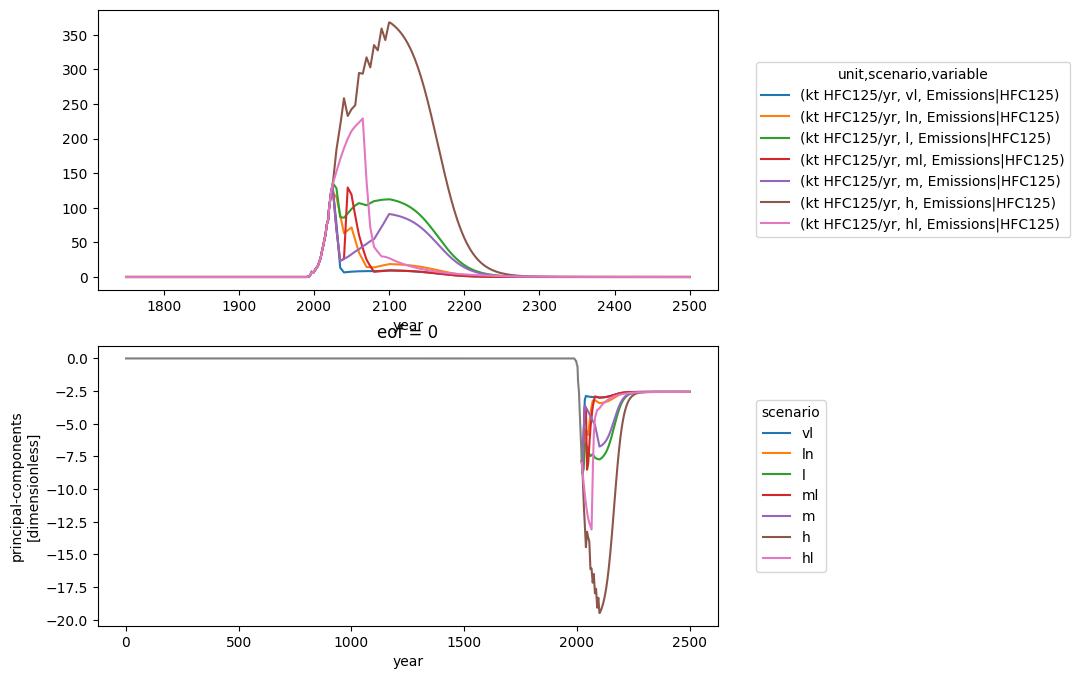

In [16]:
pc_extended = delta_pc + pc.sel(year=last_hist_year).data

fig, axes = plt.subplots(nrows=2, figsize=(8, 8))
annual_mean_emissions_emms_units.T.plot(ax=axes[0])
pc_extended.pint.to("dimensionless").plot(ax=axes[1], hue="scenario")
pc.pint.to("dimensionless").plot(ax=axes[1])
for ax in axes:
    sns.move_legend(ax, loc="center left", bbox_to_anchor=(1.05, 0.5))

## Interpolate to monthly

We have to ensure that the scenarios stay harmonised until the last month of the historical data.
Therefore, we use the same wall control point value for all scenarios.
As a simple choice, we use the average wall control point across all scenarios.

In [17]:
fixed_control_point = (
    pc_extended.sel(year=[last_hist_year, last_hist_year + 1]).mean("year").mean("scenario").data.squeeze()
)
# fixed_control_point

In [18]:
def get_wall_control_points(
    intervals_x: pint.UnitRegistry.Quantity,
    intervals_y: pint.UnitRegistry.Quantity,
    control_points_wall_x: pint.UnitRegistry.Quantity,
) -> pint.UnitRegistry.Quantity:
    """
    Get wall control points including setting our fixed control point
    """
    # Start off with standard implementation
    control_points_wall_y = get_wall_control_points_y_cubic(
        intervals_x=intervals_x,
        intervals_y=intervals_y,
        control_points_wall_x=control_points_wall_x,
    )

    # Also fix the control point between overlap year month 12 and overlap year + 1 month 1
    fixed_control_point_idxr = np.where(
        control_points_wall_x == openscm_units.unit_registry.Quantity(last_hist_year + 1, "yr")
    )
    control_points_wall_y[fixed_control_point_idxr] = fixed_control_point

    return control_points_wall_y

In [19]:
pc_extended_monthly_l = []

for scenario, sda in pc_extended.groupby("scenario"):
    scenario_monthly = interpolate_annual_mean_to_monthly(
        values=sda.data.m.squeeze(),
        values_units=pc_extended.data.u,
        years=pc_extended["year"].values,
        algorithm=LaiKaplanInterpolator(
            progress_bar=True,
            get_wall_control_points_y_from_interval_ys=get_wall_control_points,
        ),
        unit_registry=openscm_units.unit_registry,
    ).assign_coords(scenario=scenario)
    pc_extended_monthly_l.append(scenario_monthly)

pc_extended_monthly = xr.concat(pc_extended_monthly_l, dim="scenario")
pc_extended_monthly.name = "principal-components-monthly"
pc_extended_monthly.attrs["description"] = "principal component values on a monthly timestep"
pc_extended_monthly

Calculating output values:   0%|          | 0/5748 [00:00<?, ?it/s]

Calculating output values:   0%|          | 0/5748 [00:00<?, ?it/s]

Calculating output values:   0%|          | 0/5748 [00:00<?, ?it/s]

Calculating output values:   0%|          | 0/5748 [00:00<?, ?it/s]

Calculating output values:   0%|          | 0/5748 [00:00<?, ?it/s]

Calculating output values:   0%|          | 0/5748 [00:00<?, ?it/s]

Calculating output values:   0%|          | 0/5748 [00:00<?, ?it/s]

Magnitude,[[-7.746839676462855 -7.74933627606019 -7.756824757957792 ... -2.5603617500189473 -2.5603617462222696 -2.5603617424321534] [-7.746128714821365 -7.748773347726577 -7.756484831202753 ... -2.5607801914817094 -2.560779495934407 -2.5607788008860277] [-7.748307891880624 -7.750479973045106 -7.757483466422595 ... -2.560361109024408 -2.560361107865326 -2.560361106708243] ... [-7.7317647130199285 -7.737483344429958 -7.749808450590834 ... -2.560361055415449 -2.5603610544769584 -2.5603610535400887] [-7.731764713002457 -7.737483344416195 -7.749808450582651 ... -2.5603608511307017 -2.560360851032813 -2.5603608509350892] [-7.732301001983339 -7.737905690014245 -7.75005961821289 ... -2.560360851199012 -2.5603608511008438 -2.560360851002838]]
Units,dimensionless


In [20]:
months_per_year = 12
last_overlap_month = pc_extended_monthly.sel(
    time=(pc_extended_monthly["time"].dt.year == last_hist_year)
    & (pc_extended_monthly["time"].dt.month == months_per_year)
)

np.testing.assert_allclose(
    last_overlap_month.data.m.squeeze(),
    last_overlap_month.data.m[0].squeeze(),
    rtol=1e-3,
)

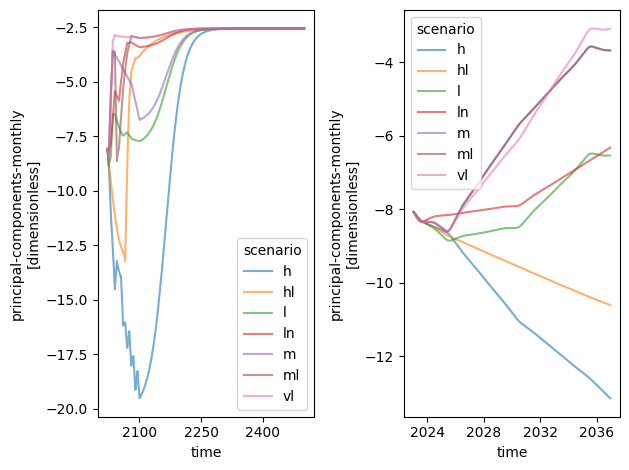

In [21]:
fig, axes = plt.subplots(ncols=2)

for years, ax in (
    (np.arange(last_hist_year + 1, 2500 + 1), axes[0]),
    (np.arange(last_hist_year + 1, last_hist_year + 15), axes[1]),
):
    pc_extended_monthly.sel(time=pc_extended_monthly["time"].dt.year.isin(years)).pint.to("dimensionless").plot(
        ax=ax, alpha=0.6, hue="scenario"
    )
    # convert_year_to_time(pc_extended.sel(year=years)).pint.to("dimensionless").plot.scatter(ax=ax, hue="scenario")

plt.tight_layout()

## Prepare output

In [22]:
if ghg != "c8f18":
    eofs = cmip7_lat_gradient_pieces_ds["eofs"]

else:
    # Calculate the EOF based on the output on ESGF.
    # In general this doesn't work,
    # but for c8f18 it's ok because seasonality is zero
    # and we want a constant latitudinal gradient in the future.
    cmip7_historical_gn_monthly_ds = load_file_from_glob(f"*{ghg}_*nz_175001-*.nc", historical_data_root_dir_p)
    cmip7_historical_gn_monthly = cmip7_historical_gn_monthly_ds[ghg]
    cmip7_historical_gn_monthly["lat"].attrs.pop("units")
    months_per_year = 12
    eofs = (
        (
            cmip7_historical_gn_monthly.sel(
                time=(cmip7_historical_gn_monthly["time"].dt.year == last_hist_year)
                & (cmip7_historical_gn_monthly["time"].dt.month == months_per_year)
            ).pint.quantify(unit_registry=ur)
            - cmip7_historical_gm_monthly.sel(
                time=(cmip7_historical_gm_monthly["time"].dt.year == last_hist_year)
                & (cmip7_historical_gm_monthly["time"].dt.month == months_per_year)
            ).pint.quantify(unit_registry=ur)
        )
        .isel(time=0)
        .assign_coords(eof=0)
        .expand_dims("eof")
    )
    eofs.name = "eofs"

out = xr.merge(
    [
        eofs,
        pc_extended_monthly.pint.to("dimensionless"),
    ],
    combine_attrs="drop_conflicts",
).pint.dequantify()

out

<xarray.Dataset> Size: 368kB
Dimensions:                       (lat: 12, eof: 1, scenario: 7, time: 5748)
Coordinates:
  * eof                           (eof) int64 8B 0
  * lat                           (lat) float64 96B -82.5 -67.5 ... 67.5 82.5
  * time                          (time) object 46kB 2022-01-15 00:00:00 ... ...
  * scenario                      (scenario) <U2 56B 'h' 'hl' 'l' ... 'ml' 'vl'
Data variables:
    eofs                          (lat, eof) float64 96B 0.4269 ... -0.2801
    principal-components-monthly  (scenario, time) float64 322kB -7.747 ... -...

In [23]:
# Double check this can work
tmp = out["eofs"] * out["principal-components-monthly"]
# tmp

## Save

In [24]:
out_file_p.parent.mkdir(exist_ok=True, parents=True)
out.to_netcdf(out_file_p)
out_file_p

PosixPath('/Users/znicholls/Documents/repos/cmip7-scenariomip-ghg-concentrations/output-bundles/1.1.0/data/interim/latitudinal-gradient/hfc125_latitudinal-gradient-info.nc')